# Correlation-Based Feature Selection with D-Wave: Pima Diabetes

**Download → Preprocess → Correlations → QUBO → D-Wave QPU → Feature subset → Classifier → Comparison**

**QUBO and D-Wave are included in this notebook.**

- [Jump to section 5: QUBO formulation](#qubo-and-dwave)
- [Jump to section 9: D-Wave quantum processor](#dwave-quantum-processor)
- [Jump to section 11: Train and compare classifiers](#classifier-comparison)

This single notebook contains the complete thesis practice workflow. Run cells from top to bottom with **Shift+Enter**, or select **Restart Kernel and Run All**.

Sections 1–4 prepare the data and calculate correlations. Sections 5–7 define and verify the QUBO with training-only parameter selection. Sections 8–12 compare solvers, train the classifier, and explain the measured results and runtime. Each section from 5 onward includes a short sentence you can use when presenting.

The reference paper uses mutual/conditional mutual information. This experiment uses Pearson correlations and a relevance–redundancy QUBO surrogate; it is not an exact reformulation of that paper's MIQUBO or classical CFS's ratio-based merit.

The saved D-Wave response is reused by default when the QUBO and sampling settings match. No token is needed to inspect that recorded result. A fresh hardware submission reads `DWAVE_API_TOKEN` from the environment or the repository's `.env`; changing parameters or disabling the cache can submit a new job.

## 0. Set up the environment

Select this repository's `.venv` Python interpreter in Jupyter or VS Code. If packages are missing, use the optional installation cell, then restart the kernel. Requirements are in the same folder as this notebook.

The classifier stages use logistic regression with `C=1`, training-fitted median imputation and standardization, and a fixed 0.5 decision threshold. Five-fold stratified cross-validation chooses the selector's $k$ and $\alpha$ using only the training partition. F1 for the positive class is the primary tuning metric.

In [1]:
# Optional setup: uncomment the appropriate line only if packages are missing,
# then restart the kernel. Ordinary Run All uses the installed environment.
# If Jupyter starts in this notebook's directory:
# %pip install -r requirements.txt
# If Jupyter starts in the repository root:
# %pip install -r "Quantum annealing for feature selection/requirements.txt"

In [2]:
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import io
import json
import os
import sys
import tempfile

# Keep plotting caches in a writable temporary directory.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "pima-matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)

RANDOM_STATE = 42
TEST_SIZE = 0.20
LIBRARY_VERSIONS = {
    name: version(name)
    for name in ["numpy", "pandas", "matplotlib", "scikit-learn"]
}
print("Python executable:", sys.executable)
display(pd.Series(LIBRARY_VERSIONS, name="version").to_frame())

# Additional tools for the QUBO, quantum sampler, and classifier stages.
from itertools import product
from time import perf_counter
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from IPython.display import Markdown
from dotenv import dotenv_values
import dimod
from dwave.samplers import SimulatedAnnealingSampler
from dwave.system import DWaveSampler, EmbeddingComposite

CPU_THREAD_LIMIT = threadpool_limits(limits=1)
CV_FOLDS = 5
K_VALUES = list(range(1, 9))
ALPHA_VALUES = [0.25, 0.50, 0.75]
NUM_READS = 1000
RUN_QPU = True
USE_QPU_CACHE = True
VERSIONS = {name: version(name) for name in [
    "numpy", "pandas", "scikit-learn", "dimod", "dwave-system", "dwave-samplers",
]}

Python executable: /Users/maishachowa/Maisha/Research/Quantum-Computing/.venv/bin/python


,version
numpy,2.5.1
pandas,3.0.1
matplotlib,3.10.8
scikit-learn,1.9.1


In [3]:
working_directory = Path.cwd().resolve()
PROJECT_DIR = None
for parent in [working_directory, *working_directory.parents]:
    for candidate in [parent, parent / "Quantum annealing for feature selection"]:
        if (candidate / "skill.md").is_file() and (candidate / "requirements.txt").is_file():
            PROJECT_DIR = candidate
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Open Jupyter from the repository root or this notebook's folder.")

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
for directory in [RAW_DIR, PROCESSED_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age",
]
TARGET = "Outcome"
COLUMNS = FEATURES + [TARGET]
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Project folder:", PROJECT_DIR)

# Keep correlation exports and QUBO results in separate locations.
QUBO_OUTPUT_DIR = OUTPUT_DIR / "qubo"
QPU_CACHE_DIR = QUBO_OUTPUT_DIR / "qpu_runs"
QPU_CACHE_DIR.mkdir(parents=True, exist_ok=True)

Project folder: /Users/maishachowa/Maisha/Research/Quantum-Computing/Quantum annealing for feature selection


## 1. Download the Pima Diabetes dataset

The historical **Pima Indians Diabetes Database** contains 768 records, eight numerical predictors, and a binary diabetes label. It concerns women aged at least 21 of Pima heritage. The original data owners were NIDDK; the CSV below is a public mirror of the historical UCI dataset.

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose measurement after an oral glucose tolerance test |
| BloodPressure | Diastolic blood pressure |
| SkinThickness | Triceps skinfold thickness |
| Insulin | Two-hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes pedigree function |
| Age | Age in years |
| Outcome | 0 = negative, 1 = positive |

The CSV has **no header row**, so we supply names explicitly. A copy is included under `data/raw/`; the next cell downloads it only if absent. A fixed SHA-256 identifies the exact bytes used in this walkthrough. A cached file lets subsequent runs work offline.

Sources: [dataset description](https://www.openml.org/api/v1/json/data/37), [mirror's original dataset notes](https://github.com/jbrownlee/Datasets/blob/master/pima-indians-diabetes.names).

In [4]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
DATA_PATH = RAW_DIR / "pima-indians-diabetes.csv"
PROVENANCE_PATH = RAW_DIR / "pima-indians-diabetes.metadata.json"
EXPECTED_SHA256 = "6bfe5d0f379d17a0e0819b996407e3c09bf80febd4287f2ed212190dfff154af"

def parse_raw_csv(payload):
    frame = pd.read_csv(io.BytesIO(payload), header=None, names=COLUMNS)
    if frame.shape != (768, 9):
        raise ValueError(f"Expected (768, 9); found {frame.shape}.")
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes):
        raise ValueError("Expected numeric measurements and labels.")
    if frame.isna().any().any() or not np.isfinite(frame.to_numpy()).all():
        raise ValueError("Unexpected missing or nonfinite values in the raw CSV.")
    if frame[TARGET].value_counts().to_dict() != {0: 500, 1: 268}:
        raise ValueError("The labels do not match the documented Pima class distribution.")
    return frame

if DATA_PATH.exists():
    payload = DATA_PATH.read_bytes()
    print("Using cached dataset:", DATA_PATH.name)
else:
    try:
        with urlopen(DATA_URL, timeout=60) as response:
            payload = response.read()
    except (URLError, TimeoutError) as exc:
        raise RuntimeError(
            "Download failed. Connect to the internet and rerun, or restore the "
            "original CSV in data/raw/pima-indians-diabetes.csv."
        ) from exc
    # Validate before writing; never cache an unexpected response.
    if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Downloaded data differs from the documented dataset checksum.")
    parse_raw_csv(payload)
    DATA_PATH.write_bytes(payload)
    metadata = {
        "name": "Pima Indians Diabetes Database",
        "download_url": DATA_URL,
        "documentation_url": "https://www.openml.org/api/v1/json/data/37",
        "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
        "sha256": EXPECTED_SHA256,
        "format": "Headerless CSV: eight predictors followed by Outcome",
        "expected_shape": [768, 9],
        "original_owners": "National Institute of Diabetes and Digestive and Kidney Diseases",
    }
    PROVENANCE_PATH.write_text(json.dumps(metadata, indent=2) + "\n")
    print("Downloaded dataset:", DATA_PATH.name)

actual_sha256 = hashlib.sha256(payload).hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("Cached data checksum differs. Inspect the file before continuing.")
df_raw = parse_raw_csv(payload)
df_raw.index.name = "record_id"
print("Shape:", df_raw.shape)
print("SHA-256:", actual_sha256)
display(df_raw.head())

Using cached dataset: pima-indians-diabetes.csv
Shape: (768, 9)
SHA-256: 6bfe5d0f379d17a0e0819b996407e3c09bf80febd4287f2ed212190dfff154af


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
record_id,,,,,,,,,
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 1.1 Inspect the original data

Keep `df_raw` unchanged so every preprocessing decision is traceable. Inspect the class balance, data types, ranges, missingness, and duplicates. Zero placeholders will not appear as `NaN` yet.

In [5]:
df_raw.info()
display(df_raw.describe().T.round(3))
class_counts = df_raw[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "count": class_counts,
    "percentage": (100 * class_counts / len(df_raw)).round(2),
}).rename_axis(TARGET))
print("Explicit missing cells:", int(df_raw.isna().sum().sum()))
print("Duplicate complete records:", int(df_raw.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


,count,percentage
Outcome,,
0,500,65.1
1,268,34.9


Explicit missing cells: 0
Duplicate complete records: 0


## 2. Data preprocessing

### 2.1 Identify zero placeholders

For this experiment, treat zeros in glucose, blood pressure, skin thickness, insulin, and BMI as missing measurements. This is a documented cleaning decision: the historical file has numeric zeros rather than explicit nulls. **A pregnancy count of zero is valid and must remain zero.**

We keep all records and all eight predictors. We do not discard insulin because it has many missing measurements, but its missingness should be discussed when interpreting results.

In [6]:
zero_report = pd.DataFrame({
    "zero_count": df_raw[FEATURES].eq(0).sum(),
    "zero_percentage": 100 * df_raw[FEATURES].eq(0).mean(),
    "treat_zero_as_missing": [feature in ZERO_AS_MISSING for feature in FEATURES],
})
display(zero_report.round(2))

df_clean = df_raw.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)
assert df_clean["Pregnancies"].equals(df_raw["Pregnancies"])
#display(df_clean[FEATURES].isna().sum().rename("missing_after_cleaning").to_frame())

,zero_count,zero_percentage,treat_zero_as_missing
Pregnancies,111,14.45,False
Glucose,5,0.65,True
BloodPressure,35,4.56,True
SkinThickness,227,29.56,True
Insulin,374,48.70,True
BMI,11,1.43,True
DiabetesPedigreeFunction,0,0.00,False
Age,0,0.00,False


### 2.2 Separate predictors and labels; reserve the test set

Use a reproducible **80/20 stratified split**. The zero-to-missing rule above is fixed and learns nothing from the data. In contrast, medians and correlation scores must be estimated using training rows only.

In [7]:
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].astype(int).copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE,
)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(X_train_raw.index) | set(X_test_raw.index) == set(df_raw.index)
assert X_train_raw.index.equals(y_train.index)
assert X_test_raw.index.equals(y_test.index)

split_summary = pd.DataFrame({
    "records": [len(X_train_raw), len(X_test_raw)],
    "negative": [int(y_train.eq(0).sum()), int(y_test.eq(0).sum())],
    "positive": [int(y_train.eq(1).sum()), int(y_test.eq(1).sum())],
}, index=["train", "test"])
split_summary["positive_percentage"] = 100 * split_summary["positive"] / split_summary["records"]
display(split_summary.round(2))

,records,negative,positive,positive_percentage
train,614,400,214,34.85
test,154,100,54,35.06


### 2.3 Fit training medians and fill missing values

The median is less sensitive to extreme measurements than the mean. Fit the imputer on the training set and reuse its fitted statistics for the test set. Preserve column names and original row indices so that predictors and labels stay aligned.

In [8]:
if X_train_raw.isna().all().any():
    raise ValueError("A training feature is completely missing; inspect it before imputing.")

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw), columns=FEATURES, index=X_train_raw.index,
)
X_test = pd.DataFrame(
    imputer.transform(X_test_raw), columns=FEATURES, index=X_test_raw.index,
)
training_medians = pd.Series(imputer.statistics_, index=FEATURES, name="training_median")

# Confirm the fitted statistics were calculated on training rows only.
np.testing.assert_allclose(training_medians.to_numpy(), X_train_raw.median().to_numpy())
for frame in [X_train, X_test]:
    assert frame.columns.tolist() == FEATURES
    assert not frame.isna().any().any()
    assert np.isfinite(frame.to_numpy()).all()
assert X_train["Pregnancies"].eq(0).sum() == X_train_raw["Pregnancies"].eq(0).sum()

display(training_medians.to_frame())
display(pd.DataFrame({
    "missing_before": X_train_raw.isna().sum(),
    "missing_after": X_train.isna().sum(),
}))
display(X_train.head())

,training_median
Pregnancies,3.0000
Glucose,117.0000
BloodPressure,72.0000
SkinThickness,29.0000
Insulin,125.0000
BMI,32.4000
DiabetesPedigreeFunction,0.3825
Age,29.0000


,missing_before,missing_after
Pregnancies,0,0
Glucose,4,0
BloodPressure,23,0
SkinThickness,175,0
Insulin,290,0
BMI,9,0
DiabetesPedigreeFunction,0,0
Age,0,0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
record_id,,,,,,,,
353,1.0,90.0,62.0,12.0,43.0,27.2,0.580,24.0
711,5.0,126.0,78.0,27.0,22.0,29.6,0.439,40.0
373,2.0,105.0,58.0,40.0,94.0,34.9,0.225,25.0
46,1.0,146.0,56.0,29.0,125.0,29.7,0.564,29.0
682,0.0,95.0,64.0,39.0,105.0,44.6,0.366,22.0


### 2.4 Check the prepared predictors

Pearson correlation is undefined for constant columns. Check for these before calculating scores.

**Do we need scaling now?** No. Pearson correlation is unchanged by positive linear rescaling, so standardizing measurements will not change these scores. A later logistic-regression or SVM pipeline can fit its scaler on the training partition.

Median imputation is a simple starting choice; it can change measured relationships, especially for a feature such as insulin with many missing entries. Later experiments can test sensitivity to the imputation method.

In [9]:
constant_features = X_train.columns[X_train.nunique(dropna=False).le(1)].tolist()
if constant_features:
    raise ValueError(f"Constant training predictors: {constant_features}")
assert y_train.nunique() == 2
display(X_train.describe().T.round(3))
print("Prepared training shape:", X_train.shape)
print("Prepared test shape:", X_test.shape)
print("Zero pregnancies retained:", int(X_train["Pregnancies"].eq(0).sum()))

,count,mean,std,min,25%,50%,75%,max
Pregnancies,614.0,3.819,3.314,0.000,1.000,3.000,6.000,17.000
Glucose,614.0,121.671,30.004,56.000,99.000,117.000,140.000,199.000
BloodPressure,614.0,72.140,12.275,24.000,64.000,72.000,80.000,122.000
SkinThickness,614.0,29.042,8.892,7.000,25.000,29.000,32.000,99.000
Insulin,614.0,137.705,78.765,15.000,120.000,125.000,130.000,744.000
BMI,614.0,32.448,6.824,18.200,27.625,32.400,36.500,67.100
DiabetesPedigreeFunction,614.0,0.477,0.330,0.084,0.245,0.382,0.639,2.329
Age,614.0,33.366,11.833,21.000,24.000,29.000,41.000,81.000


Prepared training shape: (614, 8)
Prepared test shape: (154, 8)
Zero pregnancies retained: 85


**Checkpoint:** With the default split, there are 614 training rows and 154 test rows. Both have eight predictors and no missing values after imputation.

**Practice:** Why should the median be calculated after splitting, even though it does not use the target label?

## 3. Calculate feature–target correlation

For predictor $X_i$ and binary label $y$, Pearson correlation is

$$
r_{i,y}=\frac{\sum_{t=1}^{m}(X_{ti}-\bar X_i)(y_t-\bar y)}
{\sqrt{\sum_{t=1}^{m}(X_{ti}-\bar X_i)^2\sum_{t=1}^{m}(y_t-\bar y)^2}}.
$$

Here $m$ is the number of **training** rows. Values lie between $-1$ and $1$:

- Positive: larger measurements tend to accompany label 1.
- Negative: larger measurements tend to accompany label 0.
- Near zero: weak linear association; nonlinear relationships may still exist.

For a 0/1 target this is the point-biserial correlation. Store the **signed** coefficient for interpretation and its absolute value $r_i=|r_{i,y}|$ as the later QUBO relevance score. A strong negative association can be useful too.

In [10]:
feature_target_signed = X_train.corrwith(y_train, method="pearson").reindex(FEATURES)
feature_target_signed.name = "signed_correlation"
relevance = feature_target_signed.abs().rename("absolute_correlation")

relevance_table = pd.concat([feature_target_signed, relevance], axis=1)
relevance_table.index.name = "feature"
relevance_table["rank_by_absolute_correlation"] = (
    relevance_table["absolute_correlation"].rank(ascending=False, method="min").astype(int)
)
display(relevance_table.sort_values("absolute_correlation", ascending=False).round(4))

assert np.isfinite(feature_target_signed.to_numpy()).all()
assert feature_target_signed.abs().le(1 + 1e-12).all()

,signed_correlation,absolute_correlation,rank_by_absolute_correlation
feature,,,
Glucose,0.5123,0.5123,1
BMI,0.3288,0.3288,2
Insulin,0.2459,0.2459,3
Age,0.2407,0.2407,4
SkinThickness,0.2343,0.2343,5
Pregnancies,0.2082,0.2082,6
BloodPressure,0.1834,0.1834,7
DiabetesPedigreeFunction,0.1653,0.1653,8


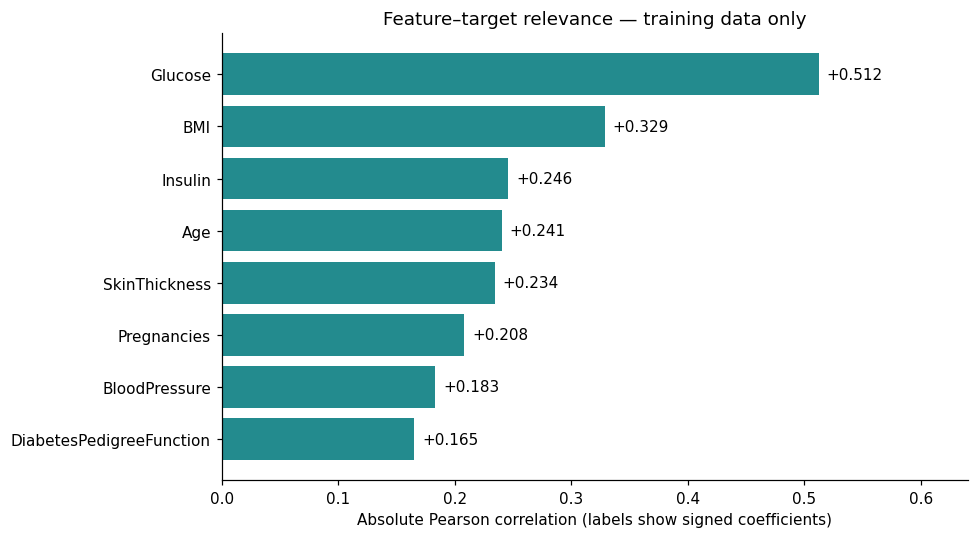

In [11]:
ranked = relevance_table.sort_values("absolute_correlation", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#238b8e" if value >= 0 else "#c56b32" for value in ranked["signed_correlation"]]
bars = ax.barh(ranked.index, ranked["absolute_correlation"], color=colors)
ax.bar_label(bars, labels=[f"{value:+.3f}" for value in ranked["signed_correlation"]], padding=5)
ax.set_xlim(0, max(0.1, ranked["absolute_correlation"].max()) * 1.25)
ax.set_xlabel("Absolute Pearson correlation (labels show signed coefficients)")
ax.set_title("Feature–target relevance — training data only")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_target_relevance.png", dpi=160, bbox_inches="tight")
plt.show()

### 3.1 Interpret the scores

The next cell reports the measured ranking for this split. A high relevance score is a useful filter signal, but does not prove causation or guarantee that a subset will classify well. Selecting only the largest individual scores also ignores redundancy between predictors.

In [12]:
top_feature = relevance.idxmax()
print(f"Largest absolute target correlation: {top_feature} ({relevance[top_feature]:.4f})")
print("This is a relevance ranking, not the final selected feature subset.")

Largest absolute target correlation: Glucose (0.5123)
This is a relevance ranking, not the final selected feature subset.


## 4. Calculate feature–feature correlation

Calculate the Pearson correlation between every pair of training predictors:

$$C_{ij}=\operatorname{corr}(X_i,X_j).$$

The signed matrix is symmetric and has ones on the diagonal, because each feature is perfectly correlated with itself.

For later QUBO construction, make a **separate** redundancy matrix:

$$
R_{ij}=\begin{cases}|C_{ij}|,&i\ne j,\\0,&i=j.\end{cases}
$$

Taking absolute values counts both strong positive and strong negative associations as potential redundancy. Setting the redundancy diagonal to zero prevents a feature from being penalized for correlating with itself. Pairwise correlation is only a proxy for redundancy; it does not capture every multivariate interaction.

In [13]:
feature_feature_signed = X_train.corr(method="pearson").loc[FEATURES, FEATURES]
redundancy = feature_feature_signed.abs().copy()
for feature in FEATURES:
    redundancy.loc[feature, feature] = 0.0

display(feature_feature_signed.round(4).rename_axis("feature"))
print("Absolute redundancy matrix (zero diagonal):")
display(redundancy.round(4).rename_axis("feature"))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
feature,,,,,,,,
Pregnancies,1.0000,0.1380,0.2023,0.0861,0.0642,0.0135,-0.0520,0.5360
Glucose,0.1380,1.0000,0.2191,0.2240,0.4508,0.2257,0.1392,0.2896
BloodPressure,0.2023,0.2191,1.0000,0.1805,0.0847,0.2696,-0.0049,0.3151
SkinThickness,0.0861,0.2240,0.1805,1.0000,0.2225,0.5386,0.1096,0.1354
Insulin,0.0642,0.4508,0.0847,0.2225,1.0000,0.2054,0.1912,0.1221
BMI,0.0135,0.2257,0.2696,0.5386,0.2054,1.0000,0.1636,0.0284
DiabetesPedigreeFunction,-0.0520,0.1392,-0.0049,0.1096,0.1912,0.1636,1.0000,0.0251
Age,0.5360,0.2896,0.3151,0.1354,0.1221,0.0284,0.0251,1.0000


Absolute redundancy matrix (zero diagonal):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
feature,,,,,,,,
Pregnancies,0.0000,0.1380,0.2023,0.0861,0.0642,0.0135,0.0520,0.5360
Glucose,0.1380,0.0000,0.2191,0.2240,0.4508,0.2257,0.1392,0.2896
BloodPressure,0.2023,0.2191,0.0000,0.1805,0.0847,0.2696,0.0049,0.3151
SkinThickness,0.0861,0.2240,0.1805,0.0000,0.2225,0.5386,0.1096,0.1354
Insulin,0.0642,0.4508,0.0847,0.2225,0.0000,0.2054,0.1912,0.1221
BMI,0.0135,0.2257,0.2696,0.5386,0.2054,0.0000,0.1636,0.0284
DiabetesPedigreeFunction,0.0520,0.1392,0.0049,0.1096,0.1912,0.1636,0.0000,0.0251
Age,0.5360,0.2896,0.3151,0.1354,0.1221,0.0284,0.0251,0.0000


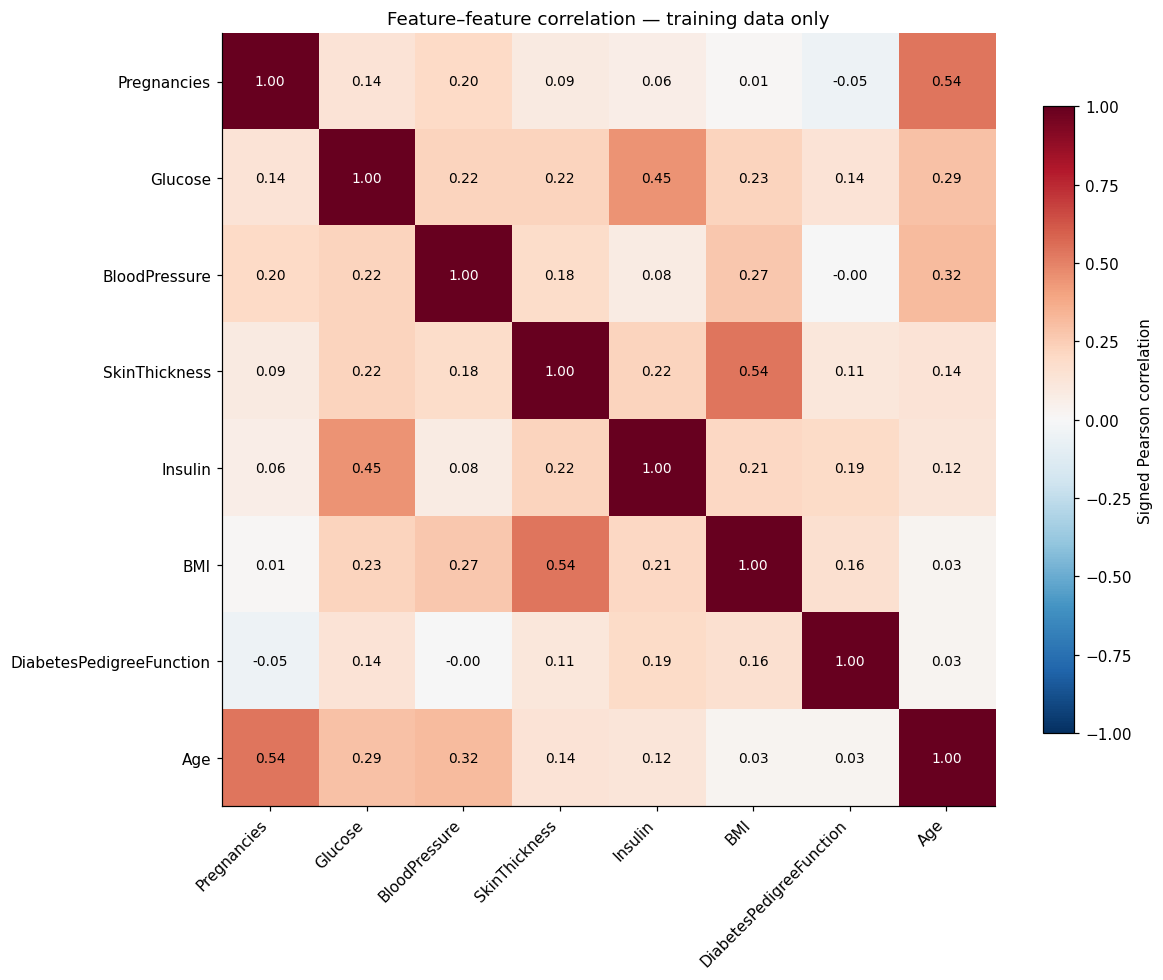

In [14]:
fig, ax = plt.subplots(figsize=(11, 9))
matrix = feature_feature_signed.to_numpy()
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for row in range(len(FEATURES)):
    for col in range(len(FEATURES)):
        ax.text(col, row, f"{matrix[row, col]:.2f}", ha="center", va="center",
                color="white" if abs(matrix[row, col]) > 0.55 else "black", fontsize=9)
fig.colorbar(image, ax=ax, label="Signed Pearson correlation", shrink=0.8)
ax.set_title("Feature–feature correlation — training data only")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_feature_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

### 4.1 Inspect unique feature pairs

There are $8(8-1)/2=28$ unique pairs. Read only the upper triangle to avoid double counting. The optional 0.5 threshold below highlights pairs for discussion; it does not delete features or decide the QUBO coefficients.

In [15]:
pair_rows = []
for i, feature_i in enumerate(FEATURES):
    for j in range(i + 1, len(FEATURES)):
        feature_j = FEATURES[j]
        coefficient = feature_feature_signed.loc[feature_i, feature_j]
        pair_rows.append({
            "feature_i": feature_i,
            "feature_j": feature_j,
            "signed_correlation": coefficient,
            "absolute_correlation": abs(coefficient),
        })
feature_pairs = pd.DataFrame(pair_rows).sort_values(
    "absolute_correlation", ascending=False, ignore_index=True,
)
assert len(feature_pairs) == 28
display(feature_pairs.round(4))

DISCUSSION_THRESHOLD = 0.5
print(f"Pairs with |r| >= {DISCUSSION_THRESHOLD} (for discussion only):")
display(feature_pairs.loc[feature_pairs["absolute_correlation"].ge(DISCUSSION_THRESHOLD)].round(4))

,feature_i,feature_j,signed_correlation,absolute_correlation
0,SkinThickness,BMI,0.5386,0.5386
1,Pregnancies,Age,0.5360,0.5360
2,Glucose,Insulin,0.4508,0.4508
3,BloodPressure,Age,0.3151,0.3151
4,Glucose,Age,0.2896,0.2896
5,BloodPressure,BMI,0.2696,0.2696
6,Glucose,BMI,0.2257,0.2257
7,Glucose,SkinThickness,0.2240,0.2240
8,SkinThickness,Insulin,0.2225,0.2225
9,Glucose,BloodPressure,0.2191,0.2191


Pairs with |r| >= 0.5 (for discussion only):


,feature_i,feature_j,signed_correlation,absolute_correlation
0,SkinThickness,BMI,0.5386,0.5386
1,Pregnancies,Age,0.5360,0.5360


<a id="qubo-and-dwave"></a>

## 5. Turn feature selection into a QUBO

**Goal:** choose useful measurements without keeping several that carry similar information.

Imagine eight on/off switches, one for each predictor:

- $x_i=1$: keep that feature.
- $x_i=0$: leave it out.

QUBO means **Quadratic Unconstrained Binary Optimization**: a score built from these 0/1 switches and pairs of switches. We call the score **energy**, and the solver tries to make it as small as possible.

Our score follows three rules:

| Rule | Effect on energy |
|---|---|
| Keep a feature related to diabetes status | Lower the energy: a reward |
| Keep two features that strongly repeat each other | Increase the energy: a redundancy cost |
| Choose a different number of features from the requested $k$ | Increase the energy: a size penalty |

$$
E(x)=\underbrace{-\alpha\sum_i r_i x_i}_{\text{reward useful features}}
+\underbrace{(1-\alpha)\sum_{i<j}R_{ij}x_ix_j}_{\text{cost of repeated information}}
+\underbrace{A\left(\sum_i x_i-k\right)^2}_{\text{cost of the wrong size}}.
$$

Here $r_i$ is the absolute feature–target correlation from section 3, and $R_{ij}$ is the absolute feature–feature correlation from section 4. $\alpha$ adjusts the relevance/redundancy trade-off. $A$ controls the size penalty.

A low energy is a good score under this correlation rule. It does **not** automatically mean the highest classification accuracy; that is tested later.

In [10]:
def build_qubo(qubo_relevance, qubo_redundancy, alpha, k):
    n = len(qubo_relevance)
    if not 0 < alpha < 1 or not 1 <= k <= n:
        raise ValueError("Require 0 < alpha < 1 and 1 <= k <= number of features.")
    penalty = float(np.max(alpha * qubo_relevance + (1 - alpha) * qubo_redundancy.sum(axis=1)) + 0.1)
    Q = {(i, i): float(-alpha * qubo_relevance[i] + penalty * (1 - 2*k)) for i in range(n)}
    for i in range(n):
        for j in range(i + 1, n):
            Q[i, j] = float((1 - alpha) * qubo_redundancy[i, j] + 2*penalty)
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q, offset=penalty*k*k)
    return bqm, Q, penalty

def original_energy(bits, qubo_relevance, qubo_redundancy, alpha, k, penalty):
    bits = np.asarray(bits, dtype=float)
    relevance_term = -alpha * np.dot(qubo_relevance, bits)
    redundancy_term = (1 - alpha) * np.sum(np.triu(qubo_redundancy, k=1) * np.outer(bits, bits))
    return float(relevance_term + redundancy_term + penalty * (bits.sum() - k)**2)

def best_feasible(sampleset, k):
    # Always choose by QUBO energy, never by held-out classifier performance.
    candidates = []
    for row in sampleset.data(fields=["sample", "energy"]):
        bits = tuple(int(row.sample[i]) for i in range(len(FEATURES)))
        if sum(bits) == k:
            candidates.append((float(row.energy), bits))
    if not candidates:
        return None
    _, bits = min(candidates, key=lambda item: (round(item[0], 12), item[1]))
    return np.asarray(bits, dtype=int)

## 6. Choose the number of features fairly

We must choose two settings: **$k$**, the number of features, and **$\alpha$**, the relevance/redundancy trade-off. We choose them using the **614 training records only**, keeping the 154 test records separate.

In [17]:
# Essential helpers for this cross-validation step and the final classifier.
# Each fold learns its own medians and correlations from training rows only.
def correlation_inputs(X_fit, y_fit):
    if not X_fit.index.equals(y_fit.index):
        raise ValueError("Predictors and labels are misaligned.")
    if X_fit.columns.tolist() != FEATURES:
        raise ValueError("Predictor order must match FEATURES.")
    if X_fit.isna().all().any():
        raise ValueError("A predictor has no observed training values.")
    fitted_imputer = SimpleImputer(strategy="median")
    imputed = pd.DataFrame(
        fitted_imputer.fit_transform(X_fit), columns=FEATURES, index=X_fit.index,
    )
    if imputed.nunique().le(1).any() or y_fit.nunique() != 2:
        raise ValueError("Correlation requires varying predictors and both target classes.")
    fold_relevance = imputed.corrwith(y_fit).abs().reindex(FEATURES).to_numpy(dtype=float)
    fold_redundancy = imputed.corr().abs().loc[FEATURES, FEATURES].to_numpy(dtype=float, copy=True)
    np.fill_diagonal(fold_redundancy, 0.0)
    assert np.isfinite(fold_relevance).all() and np.isfinite(fold_redundancy).all()
    np.testing.assert_allclose(fold_redundancy, fold_redundancy.T, atol=1e-12)
    return fitted_imputer, fold_relevance, fold_redundancy

def classifier():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE),
    )

cv = list(StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE,
).split(X_train_raw, y_train))

tuning_start = perf_counter()
cv_rows = []
topk_cv_rows = []
all_features_cv_rows = []
for fold, (fit_indices, validation_indices) in enumerate(cv, start=1):
    X_fit = X_train_raw.iloc[fit_indices]
    y_fit = y_train.iloc[fit_indices]
    X_validation = X_train_raw.iloc[validation_indices]
    y_validation = y_train.iloc[validation_indices]
    assert set(X_fit.index).isdisjoint(X_validation.index)
    fold_imputer, fold_r, fold_R = correlation_inputs(X_fit, y_fit)
    np.testing.assert_allclose(fold_imputer.statistics_, X_fit.median().to_numpy())

    all_model = classifier().fit(X_fit, y_fit)
    all_prediction = all_model.predict(X_validation)
    all_features_cv_rows.append({"fold": fold, "f1": f1_score(y_validation, all_prediction, zero_division=0),
                                 "accuracy": accuracy_score(y_validation, all_prediction)})

    relevance_order = np.argsort(-fold_r, kind="stable")
    for k in K_VALUES:
        top_features = [FEATURES[i] for i in relevance_order[:k]]
        top_model = classifier().fit(X_fit[top_features], y_fit)
        prediction = top_model.predict(X_validation[top_features])
        topk_cv_rows.append({"fold": fold, "k": k,
                            "f1": f1_score(y_validation, prediction, zero_division=0),
                            "accuracy": accuracy_score(y_validation, prediction)})
        for alpha in ALPHA_VALUES:
            fold_bqm, _, _ = build_qubo(fold_r, fold_R, alpha, k)
            exact_fold = dimod.ExactSolver().sample(fold_bqm)
            assert sum(exact_fold.first.sample.values()) == k
            bits = best_feasible(exact_fold, k)
            chosen = [FEATURES[i] for i in np.flatnonzero(bits)]
            model = classifier().fit(X_fit[chosen], y_fit)
            prediction = model.predict(X_validation[chosen])
            cv_rows.append({"fold": fold, "k": k, "alpha": alpha,
                            "f1": f1_score(y_validation, prediction, zero_division=0),
                            "accuracy": accuracy_score(y_validation, prediction),
                            "features": ", ".join(chosen)})

tuning_wall_s = perf_counter() - tuning_start
cv_details = pd.DataFrame(cv_rows)
cv_summary = cv_details.groupby(["k", "alpha"], as_index=False).agg(
    mean_f1=("f1", "mean"), std_f1=("f1", "std"), mean_accuracy=("accuracy", "mean"),
).sort_values(["mean_f1", "k", "alpha"], ascending=[False, True, True], ignore_index=True)
topk_cv_summary = pd.DataFrame(topk_cv_rows).groupby("k", as_index=False).agg(
    mean_f1=("f1", "mean"), std_f1=("f1", "std"), mean_accuracy=("accuracy", "mean"),
).sort_values(["mean_f1", "k"], ascending=[False, True], ignore_index=True)
selected_k = int(cv_summary.iloc[0]["k"])
selected_alpha = float(cv_summary.iloc[0]["alpha"])
topk_selected_k = int(topk_cv_summary.iloc[0]["k"])
print("Best five QUBO settings (training-only validation):")
display(cv_summary.head(5).round(4))
print(f"Frozen QUBO settings: k={selected_k}, alpha={selected_alpha}")
print(f"Top-correlation baseline's independently selected k: {topk_selected_k}")
print(f"Shared classical parameter-search wall time: {tuning_wall_s:.3f} seconds")

Best five QUBO settings (training-only validation):


,k,alpha,mean_f1,std_f1,mean_accuracy
0,4,0.50,0.6685,0.0211,0.7947
1,4,0.75,0.6685,0.0211,0.7947
2,5,0.75,0.6616,0.0207,0.7899
3,6,0.75,0.6615,0.0275,0.7898
4,6,0.50,0.6578,0.0270,0.7866


Frozen QUBO settings: k=4, alpha=0.5
Top-correlation baseline's independently selected k: 8
Shared classical parameter-search wall time: 0.971 seconds


## 7. Build the final problem and check the mathematics

After choosing the settings, we build one final QUBO using all training rows. Its correlation inputs must agree with sections 3 and 4.

Eight yes/no switches have $2^8=256$ possible assignments. We calculate the energy for every assignment to check that:

1. The Python implementation matches the mathematical formula.
2. Every exact minimum contains the requested number of features.

The displayed matrix contains the coefficients sent to the solvers. A diagonal entry represents one feature; an upper-triangle entry represents a pair. You do not need to read out every matrix value during the presentation.

**What to tell my supervisor:** “Before using the QPU, I checked all 256 assignments to verify that the optimization problem was implemented correctly.”

In [18]:
score_start = perf_counter()
training_imputer, qubo_relevance, qubo_redundancy = correlation_inputs(X_train_raw, y_train)
score_preparation_s = perf_counter() - score_start
# Sections 3 and 4 are the source of truth; no saved correlation file is required.
np.testing.assert_allclose(
    qubo_relevance, relevance.reindex(FEATURES).to_numpy(dtype=float), atol=1e-12,
)
np.testing.assert_allclose(
    qubo_redundancy, redundancy.loc[FEATURES, FEATURES].to_numpy(dtype=float), atol=1e-12,
)
assert qubo_relevance.shape == (len(FEATURES),)
assert qubo_redundancy.shape == (len(FEATURES), len(FEATURES))
np.testing.assert_allclose(np.diag(qubo_redundancy), 0.0, atol=1e-12)
print("Final QUBO inputs agree with the training correlations in sections 3 and 4.")

qubo_start = perf_counter()
bqm, Q, penalty = build_qubo(qubo_relevance, qubo_redundancy, selected_alpha, selected_k)
qubo_build_s = perf_counter() - qubo_start
Q_display = pd.DataFrame(0.0, index=FEATURES, columns=FEATURES)
for (i, j), coefficient in Q.items():
    Q_display.iloc[i, j] = coefficient
display(Q_display.round(4))
print(f"Penalty A: {penalty:.6f}; BQM offset: {bqm.offset:.6f}")

assignments = np.asarray(list(product([0, 1], repeat=len(FEATURES))), dtype=int)
direct_energies = np.asarray([
    original_energy(bits, qubo_relevance, qubo_redundancy, selected_alpha, selected_k, penalty)
    for bits in assignments
])
np.testing.assert_allclose(bqm.energies((assignments, list(range(8)))), direct_energies, atol=1e-10)
ground_mask = np.isclose(direct_energies, direct_energies.min(), atol=1e-9, rtol=0)
assert np.all(assignments[ground_mask].sum(axis=1) == selected_k)
print("Verified all 256 energies and feasibility of every exact ground state.")

Final QUBO inputs agree with the training correlations in sections 3 and 4.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,-8.4997,2.4677,2.4999,2.4418,2.4308,2.4055,2.4247,2.6667
Glucose,0.0000,-8.6517,2.5083,2.5107,2.6241,2.5116,2.4683,2.5435
BloodPressure,0.0000,0.0000,-8.4873,2.4890,2.4411,2.5335,2.4012,2.5563
SkinThickness,0.0000,0.0000,0.0000,-8.5127,2.5100,2.6680,2.4535,2.4665
Insulin,0.0000,0.0000,0.0000,0.0000,-8.5185,2.5014,2.4943,2.4598
BMI,0.0000,0.0000,0.0000,0.0000,0.0000,-8.5600,2.4805,2.4129
DiabetesPedigreeFunction,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-8.4782,2.4113
Age,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-8.5159


Penalty A: 1.199366; BQM offset: 19.189861
Verified all 256 energies and feasibility of every exact ground state.


In [19]:
start = perf_counter()
exact_samples = dimod.ExactSolver().sample(bqm)
exact_samples.resolve()
exact_wall_s = perf_counter() - start
exact_bits = best_feasible(exact_samples, selected_k)
exact_optimum = float(exact_samples.first.energy)
np.testing.assert_allclose(exact_optimum, direct_energies.min(), atol=1e-10)

start = perf_counter()
sa_samples = SimulatedAnnealingSampler().sample(bqm, num_reads=NUM_READS, num_sweeps=1000, seed=RANDOM_STATE)
sa_samples.resolve()
sa_wall_s = perf_counter() - start
sa_bits = best_feasible(sa_samples, selected_k)
print("Exact minimum energy:", round(exact_optimum, 8))
print("Exact selected features:", [FEATURES[i] for i in np.flatnonzero(exact_bits)])
print(f"Exact solver wall time: {exact_wall_s:.6f} seconds")
print(f"Simulated-annealing wall time: {sa_wall_s:.6f} seconds")

Exact minimum energy: -0.2413056
Exact selected features: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']
Exact solver wall time: 0.000226 seconds
Simulated-annealing wall time: 0.063309 seconds


<a id="dwave-quantum-processor"></a>

## 9. Send the QUBO to the D-Wave quantum processor

We send the QUBO coefficients to a real D-Wave **QPU** (quantum processing unit). The patient records themselves are not submitted.

The software maps our eight logical feature switches onto the chip's connections. This mapping is called **embedding**; one feature may need more than one physical qubit. The QPU then performs **1,000 reads**, returning candidate feature subsets and their energies.

We keep the lowest-energy returned subset with exactly $k$ features. We do not choose the sample by its test accuracy.

**What to tell my supervisor:** “The feature-selection step ran on an actual D-Wave annealer. I checked its answer against the exact CPU optimum.”

The access token is read privately from `DWAVE_API_TOKEN`. Identical reruns reuse the saved hardware response and are labeled as cached; loading that result does not submit a new job. If hardware access fails, the notebook reports the failure rather than substituting a classical result.

In [20]:
def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (datetime, Path)):
        return value.isoformat() if isinstance(value, datetime) else str(value)
    raise TypeError(f"Unsupported JSON type: {type(value).__name__}")

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=json_default) + "\n")

def samples_frame(sampleset):
    rows = []
    has_chain_fraction = "chain_break_fraction" in sampleset.record.dtype.names
    for row in sampleset.data():
        bits = [int(row.sample[i]) for i in range(len(FEATURES))]
        result = {name: bits[i] for i, name in enumerate(FEATURES)}
        result.update({
            "energy": float(row.energy),
            "num_occurrences": int(row.num_occurrences),
            "num_features": sum(bits),
            "feasible": sum(bits) == selected_k,
        })
        if has_chain_fraction:
            result["chain_break_fraction"] = float(row.chain_break_fraction)
        rows.append(result)
    return pd.DataFrame(rows)

qubo_specification = {
    "linear": [[i, float(bqm.linear[i])] for i in range(8)],
    "quadratic": [[i, j, float(bqm.quadratic[i, j])] for i in range(8) for j in range(i + 1, 8)],
    "offset": float(bqm.offset),
    "feature_order": FEATURES,
    "k": selected_k,
    "alpha": selected_alpha,
    "penalty": penalty,
    "num_reads": NUM_READS,
    "embedding_seed": RANDOM_STATE,
    "backend": "DWaveSampler direct QPU",
    "versions": VERSIONS,
    "source_sha256": EXPECTED_SHA256,
}
fingerprint = hashlib.sha256(json.dumps(qubo_specification, sort_keys=True).encode()).hexdigest()
save_json(QUBO_OUTPUT_DIR / "qubo_specification.json", {**qubo_specification, "fingerprint": fingerprint})

def run_or_load_qpu():
    metadata_path = QPU_CACHE_DIR / f"{fingerprint}.json"
    samples_path = QPU_CACHE_DIR / f"{fingerprint}.csv"
    submission_path = QPU_CACHE_DIR / f"{fingerprint}.submitted.json"
    if USE_QPU_CACHE and metadata_path.exists() and samples_path.exists():
        metadata = json.loads(metadata_path.read_text())
        if metadata.get("fingerprint") != fingerprint or metadata.get("status") != "completed":
            raise ValueError("Cached QPU response does not match this completed experiment.")
        frame = pd.read_csv(samples_path)
        vectors = {}
        if "chain_break_fraction" in frame:
            vectors["chain_break_fraction"] = frame["chain_break_fraction"].to_numpy()
        samples = dimod.SampleSet.from_samples(
            (frame[FEATURES].to_numpy(dtype=int), list(range(8))), dimod.BINARY,
            energy=frame["energy"].to_numpy(),
            num_occurrences=frame["num_occurrences"].to_numpy(dtype=int), **vectors,
        )
        np.testing.assert_allclose(
            bqm.energies((frame[FEATURES].to_numpy(dtype=int), list(range(8)))), frame["energy"], atol=1e-8,
        )
        metadata["loaded_from_cache"] = True
        print("Loaded a recorded hardware response; no new QPU job was submitted.")
        return samples, metadata
    if not RUN_QPU:
        return None, {"status": "disabled", "loaded_from_cache": False}
    if submission_path.exists() and not metadata_path.exists():
        # A prior job may have completed remotely even if retrieval was interrupted.
        return None, {"status": "previous_submission_unresolved", "loaded_from_cache": False,
                      "message": "Inspect the recorded job in Leap before explicitly resubmitting.",
                      "submission_record": str(submission_path)}

    environment = dotenv_values(PROJECT_DIR.parent / ".env")
    secret = os.environ.get("DWAVE_API_TOKEN") or environment.get("DWAVE_API_TOKEN")
    environment.clear()
    if not secret:
        return None, {"status": "missing_token", "loaded_from_cache": False,
                      "message": "Set DWAVE_API_TOKEN in the environment or repository .env."}
    start = perf_counter()
    problem_id = None
    try:
        with DWaveSampler(token=secret, request_timeout=30, polling_timeout=180) as qpu:
            solver_identity = str(qpu.solver.identity)
            setup_s = perf_counter() - start
            sampler = EmbeddingComposite(qpu)
            response = sampler.sample(
                bqm, num_reads=NUM_READS,
                label=f"Pima correlation QUBO k={selected_k} alpha={selected_alpha}",
                return_embedding=True, embedding_parameters={"random_seed": RANDOM_STATE},
            )
            problem_id = response.wait_id()
            save_json(submission_path, {
                "fingerprint": fingerprint, "problem_id": problem_id, "solver": solver_identity,
                "submitted_at_utc": datetime.now(timezone.utc).isoformat(),
            })
            # Ocean samples asynchronously. Resolve inside the measured interval.
            response.resolve()
            wall_s = perf_counter() - start
            context = response.info.get("embedding_context", {})
            embedding = context.get("embedding", {})
            metadata = {
                "status": "completed", "backend": "direct D-Wave QPU",
                "fingerprint": fingerprint, "loaded_from_cache": False,
                "solver": solver_identity, "problem_id": problem_id,
                "completed_at_utc": datetime.now(timezone.utc).isoformat(),
                "num_reads_requested": NUM_READS,
                "num_reads_returned": int(response.record.num_occurrences.sum()),
                "logical_variables": len(bqm),
                "physical_qubits": len({qubit for chain in embedding.values() for qubit in chain}),
                "maximum_chain_length": max((len(chain) for chain in embedding.values()), default=0),
                "embedding": {str(variable): list(chain) for variable, chain in embedding.items()},
                "chain_strength": context.get("chain_strength"),
                "embedding_timing": context.get("timing", {}),
                "topology": qpu.properties.get("topology"),
                "default_annealing_time_us": qpu.properties.get("default_annealing_time"),
                "setup_wall_s": setup_s,
                "solver_wall_s": wall_s,
                "timing_us": response.info.get("timing", {}),
            }
            frame = samples_frame(response)
            frame.to_csv(samples_path, index=False)
            save_json(metadata_path, metadata)
            print("Completed a real QPU job:", problem_id)
            return response, metadata
    except Exception as exc:
        # A sanitized summary avoids accidentally exposing a credential in saved outputs.
        message = str(exc).replace(secret, "[REDACTED]")[:700]
        metadata = {"status": "failed", "error_type": type(exc).__name__, "message": message,
                    "problem_id": problem_id, "loaded_from_cache": False,
                    "solver_wall_s": perf_counter() - start}
        save_json(QUBO_OUTPUT_DIR / "qpu_failure.json", metadata)
        print("QPU execution failed:", metadata["error_type"], message)
        return None, metadata
    finally:
        secret = None

qpu_samples, qpu_metadata = run_or_load_qpu()
qpu_bits = best_feasible(qpu_samples, selected_k) if qpu_samples is not None else None
save_json(QUBO_OUTPUT_DIR / "qpu_run_summary.json", qpu_metadata)
display(pd.Series({key: qpu_metadata.get(key) for key in [
    "status", "solver", "problem_id", "loaded_from_cache", "num_reads_returned",
    "physical_qubits", "maximum_chain_length", "solver_wall_s",
]}, name="QPU run").to_frame())
if qpu_samples is not None and qpu_bits is None:
    print("The QPU returned no size-feasible subset; its classifier row will have missing scores.")

Loaded a recorded hardware response; no new QPU job was submitted.


,QPU run
status,completed
solver,Advantage_system6;graph_id=01dae5a273
problem_id,efc6b6f3-0166-4eda-876d-19006bc1fb8c
loaded_from_cache,True
num_reads_returned,1000
physical_qubits,12
maximum_chain_length,2
solver_wall_s,5.023165


## 10. Read the selected subset and check solution quality

The key questions are:

1. **Which features were selected?** These become the classifier inputs.
2. **Did D-Wave reach the exact minimum?** An energy gap of zero, within numerical tolerance, means it matched the best QUBO score.

The read percentages tell us how consistently the sampler found a valid-size or optimal answer. One successful read can identify the optimum even if most other reads are not optimal.

**What to tell my supervisor:** “Finding the exact QUBO optimum shows that the solver solved our defined objective. It does not yet show that the chosen subset predicts diabetes better.”

Detailed diagnostic values remain available in `optimization_comparison`; the display below focuses on the main quantities.

In [21]:
def optimization_row(name, samples, wall_s, enumerator=False):
    frame = samples_frame(samples)
    count = frame["num_occurrences"].sum()
    feasible = frame["feasible"].astype(bool)
    optimal = np.isclose(frame["energy"], exact_optimum, atol=1e-8, rtol=0)
    best = frame.loc[feasible, "energy"].min() if feasible.any() else np.nan
    chain_fraction = (float(np.average(frame["chain_break_fraction"], weights=frame["num_occurrences"]))
                      if "chain_break_fraction" in frame else np.nan)
    return {
        "method": name, "best_feasible_energy": best,
        "energy_gap": float(best - exact_optimum) if feasible.any() else np.nan,
        "feasible_read_fraction": np.nan if enumerator else frame.loc[feasible, "num_occurrences"].sum() / count,
        "exact_optimum_read_fraction": np.nan if enumerator else frame.loc[optimal, "num_occurrences"].sum() / count,
        "weighted_chain_break_fraction": chain_fraction,
        "solver_wall_s": wall_s,
    }

optimization_rows = [optimization_row("Exact QUBO (CPU)", exact_samples, exact_wall_s, enumerator=True),
                     optimization_row("Simulated annealing (CPU)", sa_samples, sa_wall_s)]
if qpu_samples is not None:
    optimization_rows.append(optimization_row("D-Wave QPU", qpu_samples, qpu_metadata["solver_wall_s"]))
optimization_comparison = pd.DataFrame(optimization_rows)
display(optimization_comparison[[
    "method", "energy_gap", "feasible_read_fraction", "exact_optimum_read_fraction",
]].rename(columns={
    "method": "Solver", "energy_gap": "Gap from exact minimum",
    "feasible_read_fraction": "Valid-size read fraction",
    "exact_optimum_read_fraction": "Optimal read fraction",
}).round(4))

top_start = perf_counter()
relevance_order = np.argsort(-qubo_relevance, kind="stable")
topk_bits = np.zeros(8, dtype=int)
topk_bits[relevance_order[:topk_selected_k]] = 1
topk_wall_s = perf_counter() - top_start
matched_start = perf_counter()
matched_bits = np.zeros(8, dtype=int)
matched_bits[relevance_order[:selected_k]] = 1
matched_wall_s = perf_counter() - matched_start

selected_subsets = {
    "All features": np.ones(8, dtype=int),
    "Top correlation (CV k)": topk_bits,
    "Top correlation (matched k)": matched_bits,
    "Exact QUBO (CPU)": exact_bits,
    "Simulated annealing (CPU)": sa_bits,
    "D-Wave QPU": qpu_bits,
}
subset_rows = []
for method, bits in selected_subsets.items():
    names = [FEATURES[i] for i in np.flatnonzero(bits)] if bits is not None else []
    subset_rows.append({"method": method, "num_features": len(names) if bits is not None else np.nan,
                        "selected_features": ", ".join(names), "available": bits is not None})
subset_comparison = pd.DataFrame(subset_rows)
PRESENTATION_METHODS = [
    "All features", "Top correlation (matched k)", "Exact QUBO (CPU)",
    "Simulated annealing (CPU)", "D-Wave QPU",
]
presentation_labels = {
    "All features": "All 8 features",
    "Top correlation (matched k)": f"Top {selected_k} correlations",
    "Exact QUBO (CPU)": "Exact CPU QUBO",
    "Simulated annealing (CPU)": "Classical annealing",
    "D-Wave QPU": "D-Wave QPU",
}
if qpu_bits is not None:
    print("D-Wave selected:", ", ".join(FEATURES[i] for i in np.flatnonzero(qpu_bits)))
    print("Selection bits in the original feature order:", qpu_bits.tolist())
display(subset_comparison.loc[subset_comparison.method.isin(PRESENTATION_METHODS),
                               ["method", "num_features", "selected_features"]])

,Solver,Gap from exact minimum,Valid-size read fraction,Optimal read fraction
0,Exact QUBO (CPU),0.0,NaN,NaN
1,Simulated annealing (CPU),0.0,1.000,0.030
2,D-Wave QPU,0.0,0.983,0.037


D-Wave selected: Pregnancies, Glucose, BMI, DiabetesPedigreeFunction
Selection bits in the original feature order: [1, 1, 0, 0, 0, 1, 1, 0]


,method,num_features,selected_features
0,All features,8,"Pregnancies, Glucose, BloodPressure, SkinThick..."
2,Top correlation (matched k),4,"Glucose, Insulin, BMI, Age"
3,Exact QUBO (CPU),4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun..."
4,Simulated annealing (CPU),4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun..."
5,D-Wave QPU,4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun..."


<a id="classifier-comparison"></a>

## 11. Train the classifier and compare predictions

Feature selection chooses **which measurements to use**. The classifier makes the **diabetes predictions**. Here the classifier is ordinary, CPU-trained **logistic regression**, not a quantum classifier.

For a fair comparison, every subset uses the same classifier settings, training rows, and 154 test rows. Imputation and scaling are learned from training rows, and the prediction threshold stays at 0.5.

| Quantity | Easy interpretation |
|---|---|
| Accuracy | Percentage of test records classified correctly |
| F1 | A 0–1 score combining precision and recall for diabetes-positive cases; higher is better |
| Number of features | How many original measurements the model needs |
| Final-run time | Feature selection + classifier fitting + prediction |

The presentation compares all eight features, the top-$k$ individual correlations, exact CPU QUBO, classical annealing, and D-Wave. The top-$k$ comparison uses the same feature count as the QUBO. All computed baselines remain in `comparison`.

**What to tell my supervisor:** “I used the same classifier to isolate the effect of choosing a feature subset. I compared predictive quality, feature count, and elapsed time.”

These are descriptive results from one previously explored split. They are not an independent clinical validation, and test scores are not used to retune the selector.

In [22]:
selection_times = {
    "All features": 0.0,
    "Top correlation (CV k)": score_preparation_s + topk_wall_s,
    "Top correlation (matched k)": score_preparation_s + matched_wall_s,
    "Exact QUBO (CPU)": score_preparation_s + qubo_build_s + exact_wall_s,
    "Simulated annealing (CPU)": score_preparation_s + qubo_build_s + sa_wall_s,
    "D-Wave QPU": score_preparation_s + qubo_build_s + qpu_metadata.get("solver_wall_s", np.nan),
}
classification_rows = []
predictions = {}
fitted_classifiers = {}
for method, bits in selected_subsets.items():
    if bits is None:
        classification_rows.append({"method": method, "status": "no feasible subset / unavailable",
                                    "accuracy": np.nan, "f1": np.nan, "num_features": np.nan,
                                    "selection_wall_s": selection_times[method], "fit_s": np.nan,
                                    "predict_s": np.nan, "total_final_run_s": np.nan,
                                    "selected_features": ""})
        continue
    chosen = [FEATURES[i] for i in np.flatnonzero(bits)]
    start = perf_counter()
    model = classifier().fit(X_train_raw[chosen], y_train)
    fit_s = perf_counter() - start
    start = perf_counter()
    prediction = model.predict(X_test_raw[chosen])
    predict_s = perf_counter() - start
    fitted_classifiers[method] = model
    predictions[method] = prediction
    classification_rows.append({
        "method": method, "status": "evaluated",
        "accuracy": accuracy_score(y_test, prediction),
        "f1": f1_score(y_test, prediction, pos_label=1, zero_division=0),
        "num_features": len(chosen), "selection_wall_s": selection_times[method],
        "fit_s": fit_s, "predict_s": predict_s,
        "total_final_run_s": selection_times[method] + fit_s + predict_s,
        "selected_features": ", ".join(chosen),
    })

# A trivial classifier provides context for class imbalance; it uses no predictors.
start = perf_counter()
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
dummy_fit_s = perf_counter() - start
start = perf_counter()
dummy_prediction = dummy.predict(np.zeros((len(y_test), 1)))
dummy_predict_s = perf_counter() - start
classification_rows.append({
    "method": "Majority-class reference", "status": "evaluated",
    "accuracy": accuracy_score(y_test, dummy_prediction),
    "f1": f1_score(y_test, dummy_prediction, zero_division=0), "num_features": 0,
    "selection_wall_s": 0.0, "fit_s": dummy_fit_s, "predict_s": dummy_predict_s,
    "total_final_run_s": dummy_fit_s + dummy_predict_s, "selected_features": "",
})
comparison = pd.DataFrame(classification_rows)
presentation_comparison = comparison.loc[comparison.method.isin(PRESENTATION_METHODS),
    ["method", "accuracy", "f1", "num_features", "total_final_run_s"]].copy()
presentation_comparison["method"] = presentation_comparison["method"].map(presentation_labels)
presentation_comparison["accuracy"] *= 100
display(presentation_comparison.rename(columns={
    "method": "Approach", "accuracy": "Accuracy (%)", "f1": "F1",
    "num_features": "Features", "total_final_run_s": "Final-run time (s)",
}).round(4))
print(f"Classical parameter search (reported separately): {tuning_wall_s:.3f} seconds")

,Approach,Accuracy (%),F1,Features,Final-run time (s)
0,All 8 features,70.7792,0.5455,8,0.0041
2,Top 4 correlations,71.4286,0.5686,4,0.0059
3,Exact CPU QUBO,69.4805,0.5347,4,0.0063
4,Classical annealing,69.4805,0.5347,4,0.0691
5,D-Wave QPU,69.4805,0.5347,4,5.0290


Classical parameter search (reported separately): 0.971 seconds


### 11.1 Present the comparison visually

The four panels answer: **How accurate? What F1? How many features? How long?** The time axis is logarithmic because remote QPU submission takes much longer than local operations here.

The confusion matrices below show correct predictions and mistakes. Read the diagonal as correct predictions and the off-diagonal cells as mistakes.

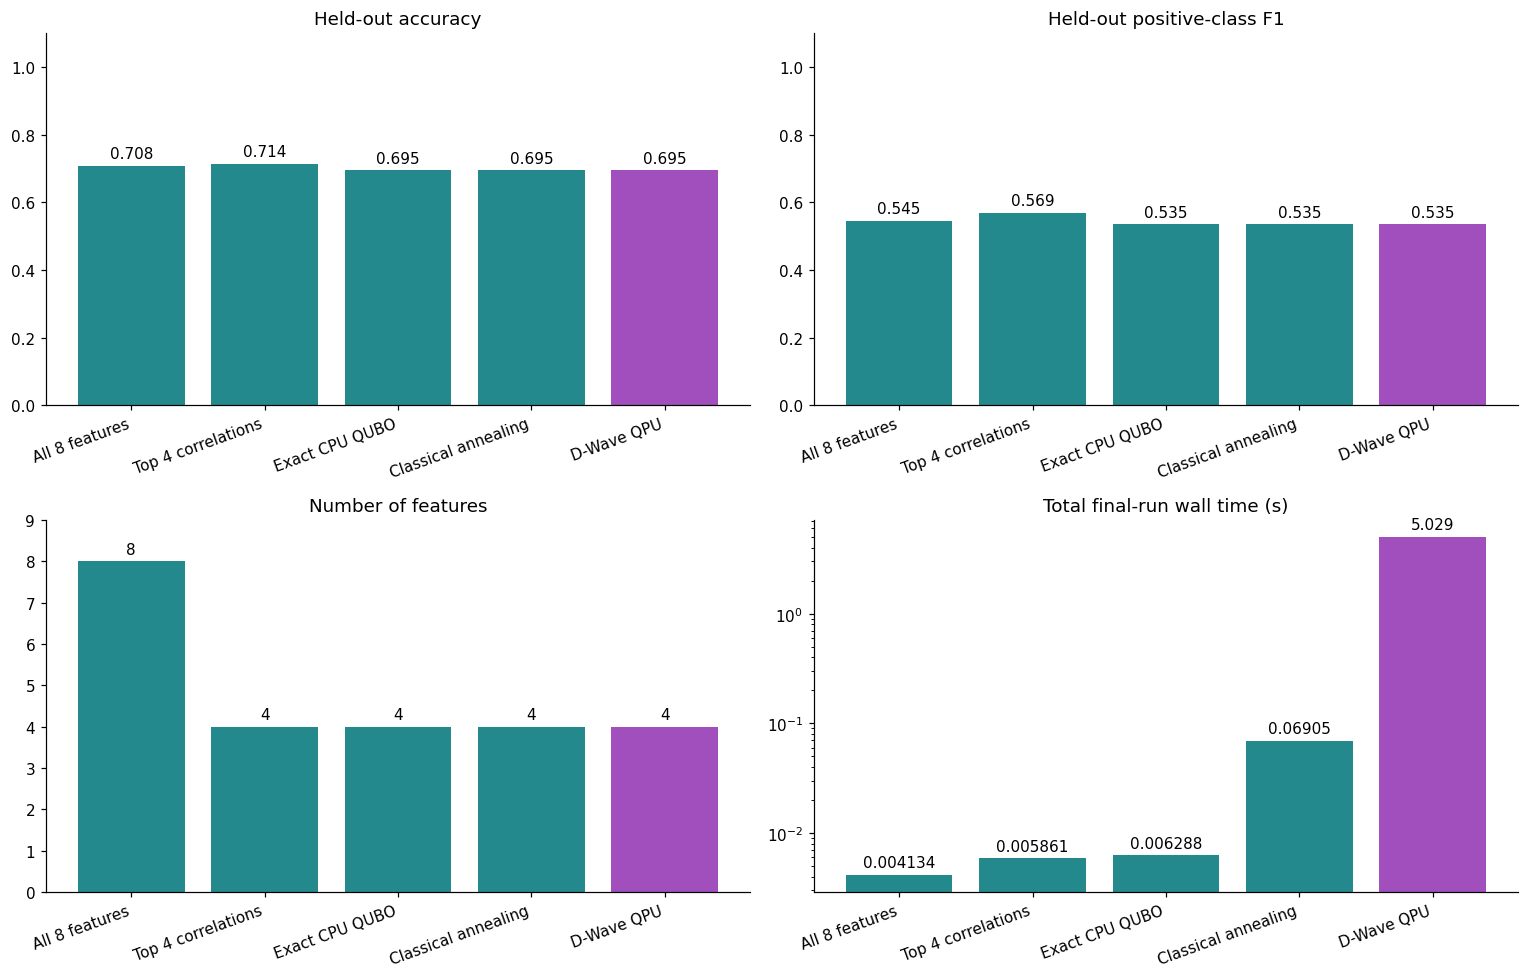

In [23]:
available = comparison.loc[comparison["status"].eq("evaluated") & comparison.method.isin(PRESENTATION_METHODS)].copy()
labels = available["method"].map(presentation_labels).tolist()
positions = np.arange(len(available))
colors = ["#a04fbd" if label == "D-Wave QPU" else "#24898c" for label in labels]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column, title in zip(axes.flat, ["accuracy", "f1", "num_features", "total_final_run_s"],
                            ["Held-out accuracy", "Held-out positive-class F1", "Number of features", "Total final-run wall time (s)"]):
    bars = ax.bar(positions, available[column], color=colors)
    ax.set_xticks(positions, labels, rotation=20, ha="right")
    ax.set_title(title)
    if column in ["accuracy", "f1"]:
        ax.set_ylim(0, 1.1)
        ax.bar_label(bars, fmt="%.3f", padding=3)
    elif column == "num_features":
        ax.set_ylim(0, 9)
        ax.bar_label(bars, fmt="%.0f", padding=3)
    else:
        ax.set_yscale("log")
        ax.bar_label(bars, labels=[f"{value:.4g}" for value in available[column]], padding=3)
fig.tight_layout()
fig.savefig(QUBO_OUTPUT_DIR / "classifier_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

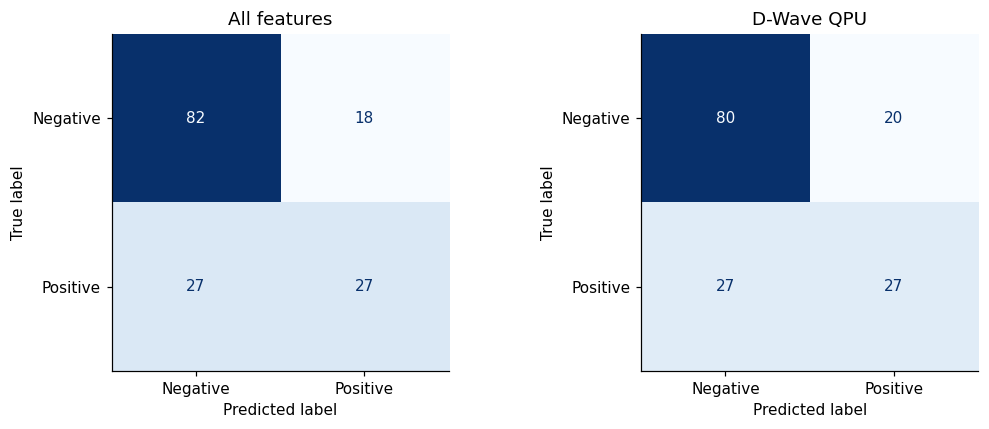

In [24]:
methods_to_plot = ["All features"]
if qpu_bits is not None:
    methods_to_plot.append("D-Wave QPU")
else:
    methods_to_plot.append("Exact QUBO (CPU)")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, methods_to_plot):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[method], display_labels=["Negative", "Positive"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(method)
fig.tight_layout()
fig.savefig(QUBO_OUTPUT_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Explain runtime and the conclusion honestly

Two times must be kept separate:

- **QPU access time:** time reported for programming and sampling on the device.
- **Client wall time:** elapsed time seen by Python, including setup, mapping, network and queue waits, and receiving the result.

Use the **final-run time** in section 11 to compare the approaches. The shared CPU parameter-search time is reported separately. Cached QPU results retain their original hardware-submission time; it is not a new measurement.

**What to tell my supervisor:** “The QPU's device time is only one part of the workflow. A short anneal does not by itself establish an end-to-end speed advantage.”

Selecting fewer features can simplify the classifier, but classical methods can offer that benefit too. With eight variables, exhaustive CPU solving is inexpensive. This experiment demonstrates a working quantum-annealing pipeline; one job and one dataset cannot establish quantum advantage.

In [25]:
timing_rows = [{"field": field, "microseconds": value, "seconds": value / 1_000_000}
               for field, value in qpu_metadata.get("timing_us", {}).items()
               if isinstance(value, (int, float))]
timing_table = pd.DataFrame(timing_rows, columns=["field", "microseconds", "seconds"])
runtime_summary = pd.DataFrame([
    {"Timing": "Device QPU access", "Seconds": qpu_metadata.get("timing_us", {}).get("qpu_access_time", np.nan) / 1_000_000},
    {"Timing": "Original QPU submission wall time", "Seconds": qpu_metadata.get("solver_wall_s", np.nan)},
    {"Timing": "QPU selection + classifier fit + prediction", "Seconds": comparison.loc[comparison.method.eq("D-Wave QPU"), "total_final_run_s"].iloc[0]},
    {"Timing": "Shared CPU parameter search (separate)", "Seconds": tuning_wall_s},
])
display(runtime_summary.round(4))
if qpu_metadata.get("status") == "completed":
    print(f"Original QPU submission wall time: {qpu_metadata['solver_wall_s']:.6f} seconds")
print("Parameter-search wall time:", round(tuning_wall_s, 6), "seconds")

,Timing,Seconds
0,Device QPU access,0.1394
1,Original QPU submission wall time,5.0232
2,QPU selection + classifier fit + prediction,5.0290
3,Shared CPU parameter search (separate),0.9713


Original QPU submission wall time: 5.023165 seconds
Parameter-search wall time: 0.971288 seconds


### A short speaking script for my supervisor

The next paragraph is generated from the current results. It distinguishes solving the QUBO successfully from improving classification or demonstrating quantum advantage.

In [26]:
baseline_result = comparison.loc[comparison.method.eq("All features")].iloc[0]
if qpu_bits is not None:
    quantum_result = comparison.loc[comparison.method.eq("D-Wave QPU")].iloc[0]
    selected_names = ", ".join(FEATURES[i] for i in np.flatnonzero(qpu_bits))
    quantum_gap = optimization_comparison.loc[
        optimization_comparison.method.eq("D-Wave QPU"), "energy_gap"
    ].iloc[0]
    matched_exact = np.isclose(quantum_gap, 0, atol=1e-8, rtol=0)
    supervisor_script = (
        "I formulated feature selection as a binary optimization problem that rewards target "
        "relevance, penalizes redundancy, and controls subset size. "
        f"Training-only cross-validation chose {selected_k} features with alpha={selected_alpha}. "
        f"The recorded D-Wave job used {qpu_metadata['num_reads_returned']} reads and "
        + ("matched the exact CPU optimum. " if matched_exact else "returned a feasible subset above the exact minimum. ")
        + f"It selected {selected_names}. "
        f"Using this subset, logistic regression achieved {100*quantum_result.accuracy:.2f}% "
        f"test accuracy and F1={quantum_result.f1:.4f}, compared with "
        f"{100*baseline_result.accuracy:.2f}% and F1={baseline_result.f1:.4f} using all features. "
        f"The feature count fell by {100*(1-quantum_result.num_features/len(FEATURES)):.0f}%. "
        "This is a reduction in the measurements needed; classical selection can also provide that benefit. "
    )
    exact_result = comparison.loc[comparison.method.eq("Exact QUBO (CPU)")].iloc[0]
    if quantum_result.total_final_run_s >= exact_result.total_final_run_s:
        supervisor_script += "The QPU did not beat exact CPU selection in total final-run time. "
    matched_baseline = comparison.loc[comparison.method.eq("Top correlation (matched k)")].iloc[0]
    if matched_baseline.f1 > quantum_result.f1:
        supervisor_script += (
            f"The simple top-{selected_k} correlation baseline had higher test F1 "
            f"({matched_baseline.f1:.4f}) in this split. "
        )
    supervisor_script += (
        "The experiment demonstrates a working quantum-annealing feature-selection pipeline, "
        "but it does not establish quantum advantage."
    )
    if np.array_equal(qpu_bits, exact_bits):
        np.testing.assert_array_equal(predictions["D-Wave QPU"], predictions["Exact QUBO (CPU)"])
else:
    supervisor_script = (
        "I implemented and checked a correlation-based QUBO feature selector, then evaluated "
        "the available classical baselines using logistic regression. The QPU result is unavailable "
        f"in this run (status: {qpu_metadata.get('status')}); I cannot claim a completed hardware result."
    )
display(Markdown("**Presentation takeaway:** " + supervisor_script))

**Presentation takeaway:** I formulated feature selection as a binary optimization problem that rewards target relevance, penalizes redundancy, and controls subset size. Training-only cross-validation chose 4 features with alpha=0.5. The recorded D-Wave job used 1000 reads and matched the exact CPU optimum. It selected Pregnancies, Glucose, BMI, DiabetesPedigreeFunction. Using this subset, logistic regression achieved 69.48% test accuracy and F1=0.5347, compared with 70.78% and F1=0.5455 using all features. The feature count fell by 50%. This is a reduction in the measurements needed; classical selection can also provide that benefit. The QPU did not beat exact CPU selection in total final-run time. The simple top-4 correlation baseline had higher test F1 (0.5686) in this split. The experiment demonstrates a working quantum-annealing feature-selection pipeline, but it does not establish quantum advantage.